# Predictor de Ingresos — Workflow de Machine Learning
**Proyecto Final — Teoría de la Computación II** · Ingeniería de Software, Universidad de La Salle

Este notebook evidencia, etapa por etapa, el workflow básico de ML visto en clase:
1. Definir la tarea → 2. Recolectar datos → 3. Representar la entrada → 4. Elegir modelo → 5. Entrenar → 6. Evaluar → 7. Usar el modelo con datos nuevos.

La lógica vive en `src/` (un módulo por etapa); el notebook la ejecuta y muestra los resultados.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from src import config, data, features, models, train, evaluate, fairness
pd.set_option('display.width', 140)

## Etapa 1 — Definir la tarea
**Clasificación binaria:** dado el perfil demográfico y laboral de una persona (Censo de EE. UU. 1994), estimar si su ingreso anual supera los **50.000 USD** (`>50K` = clase positiva `1`).

Uso previsto: **ejercicio académico** para evaluar métricas y riesgos éticos de un clasificador. No es un sistema para decidir créditos, empleos ni beneficios sobre personas reales.

## Etapa 2 — Recolectar datos
Dataset *Adult / Census Income* (UCI ML Repository, Becker & Kohavi 1996, CC BY 4.0). Se verifica la integridad del archivo con SHA-256.

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
print(json.dumps(data.describe(raw), indent=2))

{
  "rows": 48842,
  "columns": 15,
  "duplicates": 52,
  "missing_by_column": {
    "workclass": 2799,
    "occupation": 2809,
    "native_country": 857
  },
  "target_distribution": {
    "<=50K": 37155,
    ">50K": 11687
  },
  "positive_rate": 0.23928176569346055
}


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.64,13.71,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.13,105604.03,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.07,7452.02,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.50,403.00,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.42,12.39,1.0,40.0,40.0,45.0,99.0


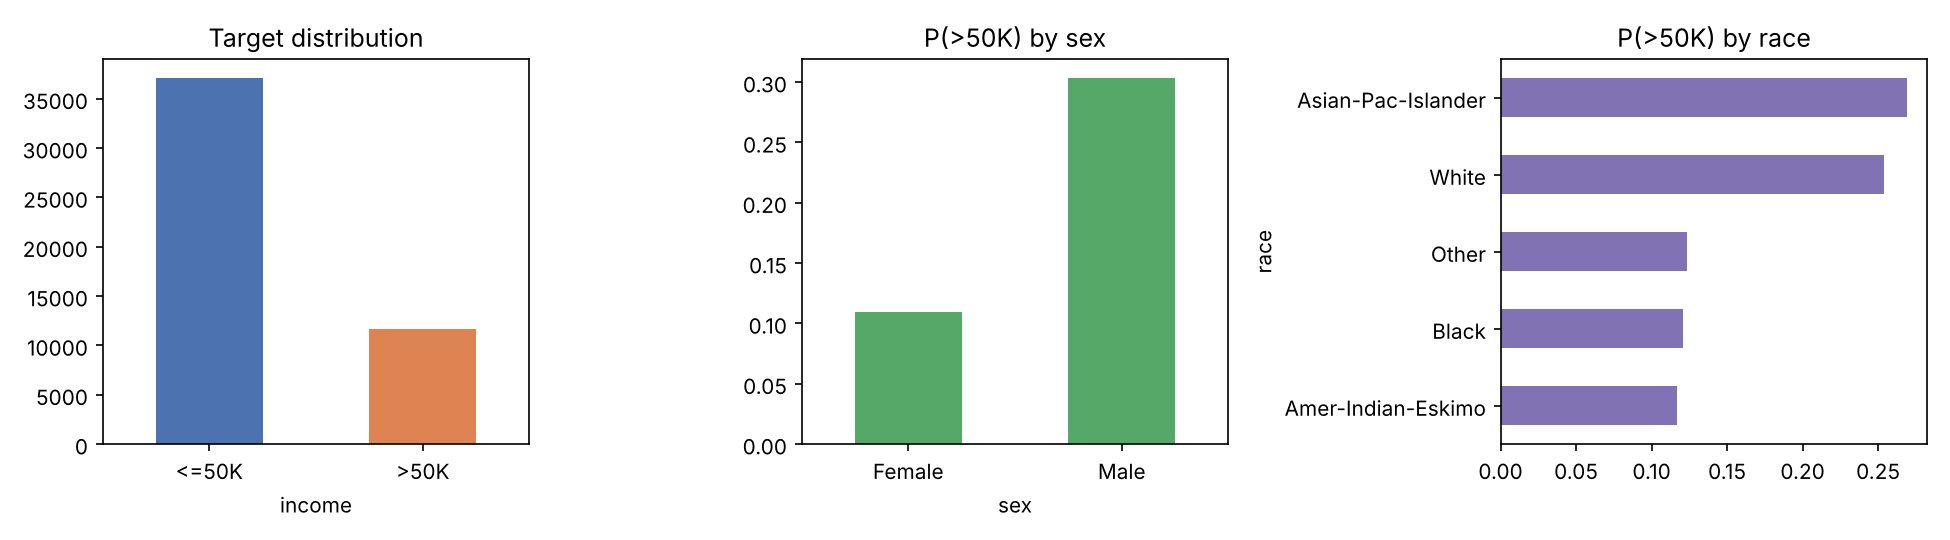

In [5]:
from src.pipeline import eda_figures
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
eda_figures(raw)
display(Image(config.FIGURES_DIR / 'eda_target_and_groups.png'))

**Hallazgos:** clases desbalanceadas (~24 % `>50K`), faltantes codificados como `?` en `workclass`, `occupation` y `native_country`, 52 registros duplicados, y una brecha histórica fuerte por sexo y raza que el modelo puede aprender y reproducir (ver análisis ético).

## Etapa 3 — Representar la entrada
- Se eliminan duplicados **antes** de partir los datos.
- Se descartan `fnlwgt` (peso muestral del censo) y `education` (redundante con `education_num`).
- Partición **estratificada 80/20** con semilla fija (42).
- Imputación + escalado + one-hot dentro de un `Pipeline`: se ajustan solo con train (sin fuga de información).

In [6]:
df = features.clean(raw)
X_train, X_test, y_train, y_test = features.split(df)
print('train', X_train.shape, 'positivos %.3f' % y_train.mean())
print('test ', X_test.shape, 'positivos %.3f' % y_test.mean())

train (39032, 12) positivos 0.239
test  (9758, 12) positivos 0.239


In [7]:
prep = features.build_preprocessor().fit(X_train)
print('Variables tras one-hot:', len(prep.get_feature_names_out()))
prep.get_feature_names_out()[:15]

Variables tras one-hot: 84


array(['num__age', 'num__education_num', 'num__capital_gain',
       'num__capital_loss', 'num__hours_per_week',
       'cat__workclass_Federal-gov', 'cat__workclass_Local-gov',
       'cat__workclass_Private', 'cat__workclass_Self-emp-inc',
       'cat__workclass_Self-emp-not-inc', 'cat__workclass_State-gov',
       'cat__workclass_Unknown', 'cat__workclass_infrequent_sklearn',
       'cat__marital_status_Divorced',
       'cat__marital_status_Married-AF-spouse'], dtype=object)

## Etapa 4 — Elegir el modelo
| Candidato | Rol |
|---|---|
| `baseline` (DummyClassifier) | Modelo de referencia: siempre predice la clase mayoritaria |
| `logreg` (Regresión Logística) | **Modelo seleccionado** (ADR-002) |
| `decision_tree` | Alternativa interpretable para comparar |
| `logreg_unaware` | Regresión Logística sin `sex`, `race`, `native_country` (experimento de equidad) |

In [8]:
cands = models.candidates()
for k, (pipe, grid) in cands.items():
    print(f'{k:15s}', type(pipe.named_steps["model"]).__name__, grid)

baseline        DummyClassifier {}
logreg          LogisticRegression {'model__C': [0.01, 0.1, 1.0, 10.0]}
decision_tree   DecisionTreeClassifier {'model__max_depth': [4, 6, 8, 10], 'model__min_samples_leaf': [20, 50]}
logreg_unaware  LogisticRegression {'model__C': [0.01, 0.1, 1.0, 10.0]}


## Etapa 5 — Entrenar
Búsqueda de hiperparámetros con validación cruzada estratificada de 5 folds usando **solo train**; luego se reentrena con todo train.

In [9]:
fitted, rows = {}, []
for name, (pipe, grid) in cands.items():
    est, params, cv = train.fit(pipe, grid, X_train, y_train)
    fitted[name] = est
    rows.append({'model': name, 'best_params': params, 'cv_f1_mean': round(cv['f1']['mean'], 4),
                 'cv_f1_std': round(cv['f1']['std'], 4), 'cv_auc_mean': round(cv['roc_auc']['mean'], 4)})
pd.DataFrame(rows)

,model,best_params,cv_f1_mean,cv_f1_std,cv_auc_mean
0,baseline,{},0.0000,0.0000,0.5000
1,logreg,{'model__C': 1.0},0.6565,0.0118,0.9051
2,decision_tree,"{'model__max_depth': 10, 'model__min_samples_l...",0.6595,0.0124,0.9047
3,logreg_unaware,{'model__C': 10.0},0.6541,0.0113,0.9039


## Etapa 6 — Evaluar el desempeño (conjunto de prueba, nunca usado en entrenamiento)

In [10]:
res = []
for name, est in fitted.items():
    pred, proba = evaluate.predict_with_threshold(est, X_test)
    res.append({'model': name, **{k: round(v, 4) for k, v in evaluate.metrics(y_test, pred, proba).items()}})
pd.DataFrame(res).set_index('model')

,accuracy,precision,recall,f1,roc_auc,tp,fp,tn,fn
model,,,,,,,,,
baseline,0.7606,0.0000,0.0000,0.0000,0.5000,0,0,7422,2336
logreg,0.8562,0.7376,0.6199,0.6736,0.9095,1448,515,6907,888
decision_tree,0.8660,0.7888,0.6010,0.6822,0.9113,1404,376,7046,932
logreg_unaware,0.8554,0.7385,0.6130,0.6699,0.9090,1432,507,6915,904


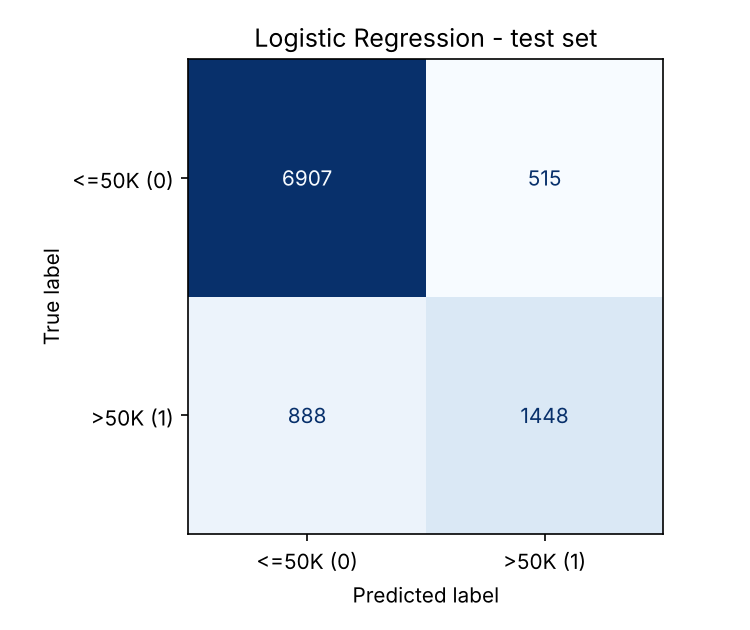

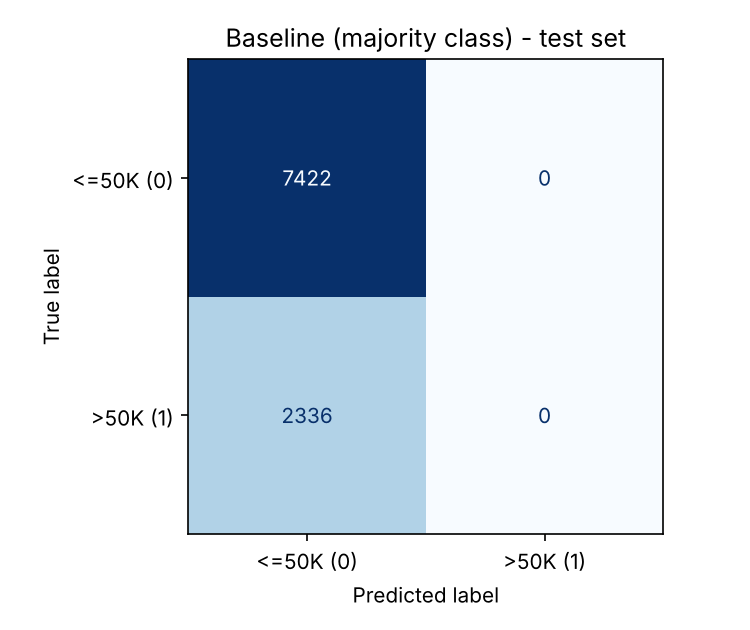

In [11]:
display(Image(config.FIGURES_DIR / 'confusion_matrix_logreg.png'))
display(Image(config.FIGURES_DIR / 'confusion_matrix_baseline.png'))

- **VP (1448):** personas con ingreso `>50K` correctamente identificadas.
- **FP (515):** personas con `<=50K` que el modelo clasificó como `>50K`.
- **VN (6907):** personas con `<=50K` correctamente identificadas.
- **FN (888):** personas con `>50K` que el modelo no detectó → explica el recall de 0.62.

El *baseline* obtiene 76 % de accuracy sin detectar a nadie de la clase positiva: por eso la accuracy sola engaña con datos desbalanceados.

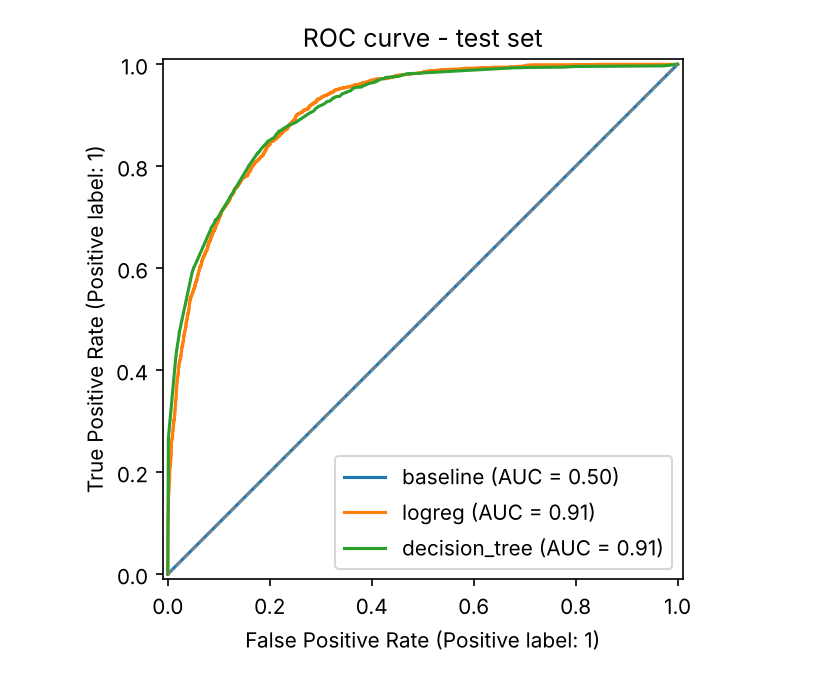

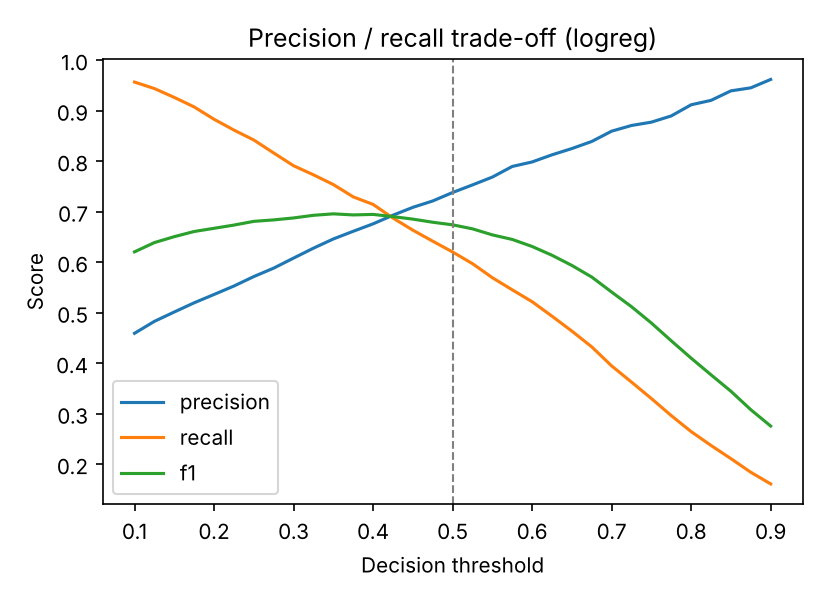

In [12]:
display(Image(config.FIGURES_DIR / 'roc_curve.png'))
display(Image(config.FIGURES_DIR / 'threshold_tradeoff.png'))

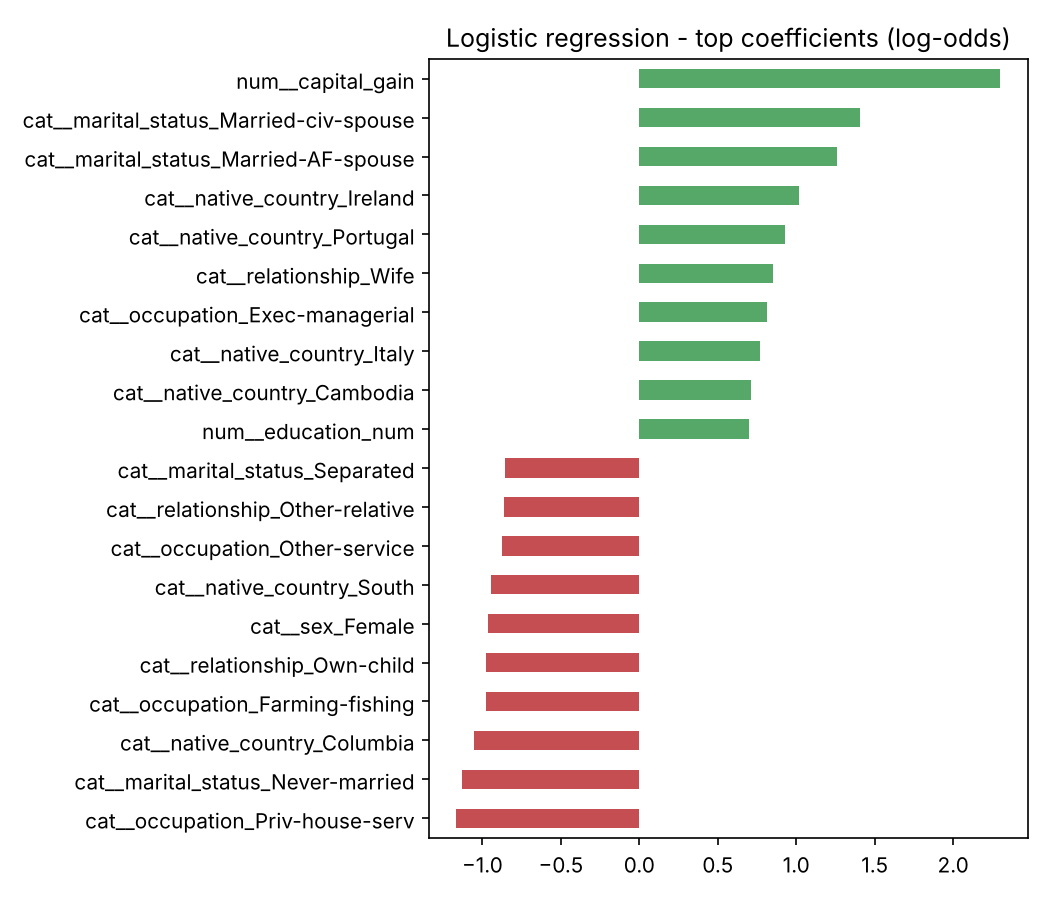

In [13]:
display(Image(config.FIGURES_DIR / 'logreg_coefficients.png'))

### Criterios de aceptación del software

In [14]:
r = json.loads((config.REPORTS_DIR / 'metrics.json').read_text(encoding='utf-8'))
pd.Series(r['acceptance']['checks'], name='cumple').to_frame()

,cumple
f1_test >= min_f1,True
roc_auc_test >= min_roc_auc,True
accuracy gain vs baseline >= 0.05,True
|f1_train - f1_test| <= 0.03,True
cv f1 std <= 0.02,True


### Auditoría de equidad (sexo y raza)

In [15]:
pred, _ = evaluate.predict_with_threshold(fitted['logreg'], X_test)
for attr in ['sex', 'race']:
    t = fairness.group_metrics(y_test, pred, X_test[attr])
    display(t.round(3)); print(attr, {k: round(v, 3) for k, v in fairness.gaps(t).items()})

,group,n,base_rate,selection_rate,tpr,fpr,accuracy
0,Male,6432,0.304,0.269,0.648,0.104,0.821
1,Female,3326,0.115,0.070,0.478,0.017,0.925


sex {'demographic_parity_diff': 0.199, 'equal_opportunity_diff': 0.17, 'fpr_diff': 0.087, 'disparate_impact_ratio': 0.259}


,group,n,base_rate,selection_rate,tpr,fpr,accuracy
0,White,8353,0.255,0.216,0.628,0.074,0.850
1,Black,916,0.123,0.079,0.460,0.025,0.912
2,Asian-Pac-Islander,311,0.228,0.244,0.676,0.117,0.836


race {'demographic_parity_diff': 0.166, 'equal_opportunity_diff': 0.216, 'fpr_diff': 0.092, 'disparate_impact_ratio': 0.322}


In [16]:
pred_u, _ = evaluate.predict_with_threshold(fitted['logreg_unaware'], X_test)
t = fairness.group_metrics(y_test, pred_u, X_test['sex'])
print('Sin atributos sensibles ->', {k: round(v, 3) for k, v in fairness.gaps(t).items()})

Sin atributos sensibles -> {'demographic_parity_diff': 0.192, 'equal_opportunity_diff': 0.146, 'fpr_diff': 0.084, 'disparate_impact_ratio': 0.273}


Quitar `sex` y `race` casi no reduce la brecha: variables *proxy* como `relationship` (Husband/Wife) y `marital_status` siguen codificando el sexo. La "ceguera" a los atributos sensibles no garantiza equidad.

## Etapa 7 — Usar el modelo entrenado con datos nuevos

In [17]:
from src.predict import predict, load_model
new_people = pd.read_csv(ROOT / 'data' / 'sample_new_people.csv')
predict(new_people, model=load_model())[['age','education_num','occupation','sex','hours_per_week','proba_gt_50k','prediction']]

,age,education_num,occupation,sex,hours_per_week,proba_gt_50k,prediction
0,30,12,Handlers-cleaners,Male,40,0.0288,<=50K
1,37,10,Craft-repair,Male,40,0.2946,<=50K
2,28,11,Prof-specialty,Male,50,1.0000,>50K
3,45,13,Prof-specialty,Male,50,0.3007,<=50K
4,22,9,Machine-op-inspct,Male,50,0.0229,<=50K


In [18]:
# Mismo registro con umbral 0.35 (mejor F1 según el análisis de umbral)
predict(new_people, model=load_model(), threshold=0.35)[['proba_gt_50k','prediction']]

,proba_gt_50k,prediction
0,0.0288,<=50K
1,0.2946,<=50K
2,1.0000,>50K
3,0.3007,<=50K
4,0.0229,<=50K


## Conclusión
La Regresión Logística supera claramente al modelo de referencia (F1 0.67 vs 0.00; AUC 0.91 vs 0.50), es estable entre folds y no presenta sobreajuste; cumple los 5 criterios de aceptación. Sin embargo, reproduce las brechas del censo de 1994: detecta peor a mujeres y personas negras con ingresos altos. Las conclusiones y recomendaciones completas están en `docs/Informe_Actividad6.pdf`.